# Synthetic KYC — Customer Profiles

The Sparkov transaction data only carries basic demographics (name, address, job, date of birth). Real card issuers also hold a **KYC (Know Your Customer)** file for every customer: declared income, expected spending, how their identity was verified, a risk rating, and so on. This notebook generates an **artificial KYC table** for all 999 customers.

Input: `data/fraudTrain.csv`, `data/fraudTest.csv` (customer attributes only)

Output: `data/kyc_customers.csv` (one row per customer, keyed by `cc_num`)

This notebook covers:
1. Customer base
2. Employment and income
3. Declared profile and credit
4. Account opening and onboarding
5. Identity verification and screening
6. KYC risk rating and review cycle
7. The KYC table (data dictionary)
8. Save
9. Label-independence check

### Design principle: no fraud labels

Every field is generated from attributes already in the data (age, job title, city population, first transaction date) plus seeded random noise. **`is_fraud` is never used to generate anything.** It is read only once, in section 9, after the table has been saved, to show that no fraud signal was planted.

This matters because of how fraud works in this dataset: each customer is defrauded **at most once**, in a single burst of ~10 transactions over 1–2 days, and never again. Of the 603 customers defrauded in the model's fit period, **0%** are defrauded again in validation or test. A KYC "risk" field built from past fraud labels would therefore point the wrong way, and one built from all labels would simply leak the test answers. Label-independent KYC is the only version whose effect on the model is a genuine finding.

All randomness comes from one seed, so the table is identical every time the notebook runs. **The data is entirely fictional.** It describes the simulated Sparkov customers and contains no new personal information (no names, IDs, phone numbers or emails).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
%matplotlib inline

DATA_DIR = Path("data")
SEED = 4102
SNAPSHOT_DATE = pd.Timestamp("2019-01-01")  # the KYC file as it stood when the transaction data starts

rng = np.random.default_rng(SEED)

BLUE, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#898781", "#e6e5e1"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 12,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "figure.dpi": 110,
})

## 1. Customer base

One row per card (`cc_num`). Each card belongs to exactly one person, and each person has exactly one card. Only label-free columns are read.

In [2]:
columns = ["cc_num", "gender", "dob", "job", "city_pop", "state", "trans_date_trans_time"]
transactions = pd.concat([
    pd.read_csv(DATA_DIR / "fraudTrain.csv", usecols=columns),
    pd.read_csv(DATA_DIR / "fraudTest.csv", usecols=columns),
])
transactions["trans_date_trans_time"] = pd.to_datetime(transactions["trans_date_trans_time"])

customers = (
    transactions.groupby("cc_num")
    .agg(
        dob=("dob", "first"),
        job=("job", "first"),
        city_pop=("city_pop", "first"),
        first_txn=("trans_date_trans_time", "min"),
    )
    .reset_index()
)
customers["dob"] = pd.to_datetime(customers["dob"])
customers["age"] = (SNAPSHOT_DATE - customers["dob"]).dt.days / 365.25
n = len(customers)

print(f"{n:,} customers, aged {customers['age'].min():.0f}–{customers['age'].max():.0f} at the snapshot date")
customers.head()

999 customers, aged 14–94 at the snapshot date


,cc_num,dob,job,city_pop,first_txn,age
0,60416207185,1986-02-17,Information systems manager,1645,2019-01-01 12:47:15,32.870637
1,60422928733,1942-04-02,Secondary school teacher,46944,2019-01-03 18:38:26,76.750171
2,60423098130,1958-07-28,Barrister's clerk,83,2019-01-01 06:48:36,60.429843
3,60427851591,1976-06-30,Politician's assistant,2142,2019-01-01 07:36:27,42.505133
4,60487002085,1972-08-15,"Horticulturist, commercial",233060,2019-01-06 03:23:55,46.379192


## 2. Employment and income

**Employment status**
- **Retired:** from age 65, with the probability rising 6 points per year (50% at 65, capped at 95%)
- **Student:** everyone under 18, and 35% of 18–23-year-olds
- **Self-employed:** 12% of the remaining working-age customers
- **Employed:** everyone else

**Annual income** = $55k base × job factor × age curve × city factor × random noise
- **Job factor:** 1.6 for high-paying titles (engineer, doctor, lawyer, director, …), 0.7 for lower-paying ones (assistant, clerk, technician, …), otherwise 1.0
- **Age curve:** peaks at age 50, about 0.6× at 20 and at 80
- **City factor:** slightly higher in larger cities (0.85–1.25×)
- **Noise:** log-normal (σ = 0.35), so incomes are right-skewed like real ones
- **Adjustments:** retired 0.6× (pension), students 0.3× (capped at $25k), self-employed get extra spread

**Source of funds** follows employment (salary, business income, pension, allowance), with 40% of customers earning over $150k declaring investments instead.

In [3]:
age = customers["age"].to_numpy()
job = customers["job"].str.lower()

u = rng.random(n)
p_retired = np.where(age >= 65, np.clip(0.5 + 0.06 * (age - 65), 0, 0.95), 0.0)
p_student = np.select([age < 18, age < 24], [1.0, 0.35], default=0.0)
employment = np.where(u < p_retired, "Retired", np.where(u < p_retired + p_student, "Student", "Employed")).astype(object)
employment[(employment == "Employed") & (rng.random(n) < 0.12)] = "Self-employed"

HIGH_PAY = ["surgeon", "physician", "doctor", "lawyer", "solicitor", "barrister", "director", "chief",
            "executive", "engineer", "dentist", "pharmacist", "actuary", "architect", "consultant",
            "manager", "scientist", "investment", "banker", "pilot", "analyst"]
LOW_PAY = ["assistant", "clerk", "worker", "administrator", "technician", "porter", "cleaner",
           "operative", "receptionist", "cashier", "carer"]
job_factor = np.where(job.str.contains("|".join(HIGH_PAY)), 1.6,
                      np.where(job.str.contains("|".join(LOW_PAY)), 0.7, 1.0))
age_curve = 0.55 + 0.45 * np.exp(-((age - 50) / 18) ** 2)
city_factor = np.clip(1 + 0.06 * (np.log10(customers["city_pop"].to_numpy()) - 4), 0.85, 1.25)

income = 55_000 * job_factor * age_curve * city_factor * rng.lognormal(0, 0.35, n)
income = np.where(employment == "Retired", income * 0.6, income)
income = np.where(employment == "Student", np.minimum(income * 0.3, 25_000), income)
income = np.where(employment == "Self-employed", income * rng.lognormal(0, 0.4, n), income)
annual_income = np.maximum(np.round(income / 1000) * 1000, 8_000)

source_of_funds = np.select(
    [employment == "Retired", employment == "Student", employment == "Self-employed"],
    ["Pension", "Allowance / part-time work", "Business income"],
    default="Salary",
)
source_of_funds[(annual_income > 150_000) & (rng.random(n) < 0.4)] = "Investments"

income_band = pd.cut(
    annual_income, [0, 30_000, 60_000, 100_000, 150_000, np.inf],
    labels=["<30k", "30–60k", "60–100k", "100–150k", "150k+"], right=False,
)

pd.Series(employment).value_counts()

Employed         688
Retired          164
Self-employed    105
Student           42
Name: count, dtype: int64

## 3. Declared profile and credit

At onboarding, customers declare how they expect to use the card. These **declared** values are what transaction monitoring compares actual behaviour against.

- **Declared monthly spend:** 15–40% of monthly income, rounded to $50
- **Declared transactions per month:** log-normal around 45. This is deliberately independent of how often the customer actually transacts, because real declarations are rough guesses.
- **Credit score** (300–850): centred on 680, a little higher for older and higher-income customers
- **Credit limit:** 15–35% of income, scaled by credit score, rounded to $500, between $1,000 and $50,000

In [4]:
declared_monthly_spend = np.round(annual_income / 12 * rng.uniform(0.15, 0.40, n) / 50) * 50
declared_txn_per_month = np.round(rng.lognormal(np.log(45), 0.4, n)).astype(int)

credit_score = np.clip(
    np.round(rng.normal(680, 55, n) + 1.0 * (age - 45) + 30 * np.log(annual_income / 55_000)),
    300, 850,
).astype(int)

limit = annual_income * rng.uniform(0.15, 0.35, n) * np.clip((credit_score - 500) / 250, 0.3, 1.4)
credit_limit = np.clip(np.round(limit / 500) * 500, 1_000, 50_000)

pd.DataFrame({
    "annual_income": annual_income,
    "declared_monthly_spend": declared_monthly_spend,
    "declared_txn_per_month": declared_txn_per_month,
    "credit_score": credit_score,
    "credit_limit": credit_limit,
}).describe().round(0)

,annual_income,declared_monthly_spend,declared_txn_per_month,credit_score,credit_limit
count,999.0,999.0,999.0,999.0,999.0
mean,49916.0,1134.0,48.0,675.0,9179.0
std,29834.0,771.0,20.0,60.0,7373.0
min,8000.0,100.0,10.0,461.0,1000.0
25%,29000.0,600.0,34.0,634.0,4000.0
50%,44000.0,950.0,45.0,678.0,7500.0
75%,65000.0,1450.0,58.0,716.0,12500.0
max,214000.0,5650.0,141.0,850.0,50000.0


## 4. Account opening and onboarding

- **Account open date:**
  - For customers active from the start of the data, tenure is drawn from a gamma distribution (mean 8 years), capped so nobody opened an account before age 18.
  - Customers whose first transaction comes more than 60 days after the snapshot date are treated as **new customers**, opening 1–12 months before that first transaction.
  - Every account opens at least 30 days before its first transaction.
- **Onboarding channel** depends on when the account was opened:

  | Opened | Branch | Online | Mobile app |
  |---|---|---|---|
  | before 2008 | 85% | 15% | 0% |
  | 2008–2014 | 50% | 40% | 10% |
  | 2015 onwards | 25% | 35% | 40% |

  Customers under 35 at opening shift 15 points from branch to mobile, from 2008 onwards.
- **Residency status:** 90% citizen, 7% permanent resident, 3% visa holder (visa holders are under 60)
- **Number of products** (card, current account, savings, …): 1 plus a count that grows with tenure, capped at 5

In [5]:
first_txn = customers["first_txn"]
new_customer = (first_txn > SNAPSHOT_DATE + pd.Timedelta(days=60)).to_numpy()

tenure_years = np.minimum(rng.gamma(2.0, 4.0, n), np.clip(age - 18, 0.5, None))
open_existing = SNAPSHOT_DATE - pd.to_timedelta(tenure_years * 365.25, unit="D")
open_new = first_txn - pd.to_timedelta(rng.uniform(30, 365, n), unit="D")
account_open_date = pd.Series(pd.to_datetime(np.where(new_customer, open_new, open_existing)), index=customers.index)
latest_allowed = first_txn - pd.Timedelta(days=30)
account_open_date = account_open_date.where(account_open_date < latest_allowed, latest_allowed).dt.normalize()

open_year = account_open_date.dt.year.to_numpy()
age_at_open = ((account_open_date - customers["dob"]).dt.days / 365.25).to_numpy()

p_branch = np.select([open_year < 2008, open_year < 2015], [0.85, 0.50], default=0.25)
p_online = np.select([open_year < 2008, open_year < 2015], [0.15, 0.40], default=0.35)
young_shift = np.where((age_at_open < 35) & (open_year >= 2008), 0.15, 0.0)
p_branch = p_branch - young_shift
u = rng.random(n)
onboarding_channel = np.where(u < p_branch, "Branch", np.where(u < p_branch + p_online, "Online", "Mobile app"))

residency_status = rng.choice(["Citizen", "Permanent resident", "Visa holder"], size=n, p=[0.90, 0.07, 0.03])
residency_status[(residency_status == "Visa holder") & (age >= 60)] = "Citizen"

reference_date = account_open_date.where(new_customer, SNAPSHOT_DATE)
tenure_at_reference = ((reference_date - account_open_date).dt.days / 365.25).to_numpy()
num_products = np.clip(1 + rng.poisson(0.15 * np.minimum(tenure_at_reference, 15)), 1, 5)

print(f"New customers (opened after the snapshot): {new_customer.sum()}")
pd.crosstab(pd.cut(open_year, [1900, 2007, 2014, 2100], labels=["<2008", "2008–14", "2015+"]),
            onboarding_channel, normalize="index",
            rownames=["opened"], colnames=["channel"]).round(2)

New customers (opened after the snapshot): 77


channel,Branch,Mobile app,Online
opened,,,
<2008,0.80,0.00,0.20
2008–14,0.42,0.14,0.44
2015+,0.20,0.44,0.36


## 5. Identity verification and screening

**ID verification method** follows the onboarding channel:

| Channel | Method |
|---|---|
| Branch | Document checked in person |
| Online | Database check only (always before 2012, otherwise 50%) or document upload |
| Mobile app | Document + biometric (selfie) match (80%) or document upload |

**Verified contact details:**
- **Address:** 97% for branch, 88% for online, 93% for mobile
- **Phone:** 85% for accounts opened before 2012, otherwise 97%
- **Email:** 70% for accounts opened before 2010, otherwise 95%

**Screening:**
- **PEP (politically exposed person):** 0.4%, rising to 2.4% for incomes over $150k
- **Sanctions screening:** 1% are a "potential match – cleared" (a name similarity that was investigated and dismissed)

In [6]:
u = rng.random(n)
id_verification_method = np.select(
    [
        onboarding_channel == "Branch",
        (onboarding_channel == "Online") & ((open_year < 2012) | (u < 0.5)),
        onboarding_channel == "Online",
        (onboarding_channel == "Mobile app") & (u < 0.8),
    ],
    ["Document (in person)", "Database check", "Document upload", "Document + biometric"],
    default="Document upload",
)

p_address = np.select([onboarding_channel == "Branch", onboarding_channel == "Online"], [0.97, 0.88], default=0.93)
address_verified = rng.random(n) < p_address
phone_verified = rng.random(n) < np.where(open_year < 2012, 0.85, 0.97)
email_verified = rng.random(n) < np.where(open_year < 2010, 0.70, 0.95)

pep_flag = rng.random(n) < (0.004 + 0.02 * (annual_income > 150_000))
sanctions_screening = np.where(rng.random(n) < 0.01, "Potential match – cleared", "Clear")

pd.Series(id_verification_method).value_counts()

Document (in person)    406
Database check          252
Document + biometric    181
Document upload         160
Name: count, dtype: int64

## 6. KYC risk rating and review cycle

Banks assign each customer a risk rating from rule-based **risk points**:

| Factor | Points |
|---|---|
| PEP | +3 |
| Address not verified | +2 |
| Sanctions potential match (cleared) | +2 |
| Visa holder | +1 |
| Identity verified by database check only | +1 |
| Phone not verified | +1 |
| Customer for less than 1 year | +1 |
| Self-employed (business income harder to verify) | +1 |

The rating is **Low** for 0–1 points, **Medium** for 2–3 and **High** for 4 or more.

The rating sets how often the KYC file must be reviewed: every 3 years (Low), 2 years (Medium) or 1 year (High). The last review date is drawn so that about 20% of existing customers' files are **overdue** at the snapshot date (about 15% overall), which is typical of real KYC backlogs. New customers were reviewed at opening.

In [7]:
risk_points = (
    3 * pep_flag
    + 2 * ~address_verified
    + 2 * (sanctions_screening != "Clear")
    + 1 * (residency_status == "Visa holder")
    + 1 * (id_verification_method == "Database check")
    + 1 * ~phone_verified
    + 1 * (tenure_at_reference < 1)
    + 1 * (employment == "Self-employed")
)
kyc_risk_rating = np.select([risk_points >= 4, risk_points >= 2], ["High", "Medium"], default="Low")

review_cycle_years = pd.Series(kyc_risk_rating).map({"Low": 3, "Medium": 2, "High": 1}).to_numpy()
days_since_review = rng.uniform(0, review_cycle_years * 365 * 1.25)
last_review = reference_date - pd.to_timedelta(days_since_review, unit="D")
last_kyc_review_date = last_review.where(last_review > account_open_date, account_open_date)
last_kyc_review_date = last_kyc_review_date.where(~new_customer, account_open_date).dt.normalize()
kyc_review_overdue = ((reference_date - last_kyc_review_date).dt.days > review_cycle_years * 365).to_numpy()

print(f"Overdue reviews: {kyc_review_overdue.mean():.1%}")
pd.Series(kyc_risk_rating).value_counts()

Overdue reviews: 13.5%


Low       857
Medium    129
High       13
Name: count, dtype: int64

## 7. The KYC table

| Column | Description |
|---|---|
| `cc_num` | Card number, the join key to the transaction data |
| `customer_id` | Synthetic KYC record ID |
| `account_open_date` | Date the account was opened |
| `onboarding_channel` | Branch, Online or Mobile app |
| `residency_status` | Citizen, Permanent resident or Visa holder |
| `employment_status` | Employed, Self-employed, Retired or Student |
| `source_of_funds` | Salary, Business income, Pension, Allowance / part-time work or Investments |
| `annual_income` | Declared annual income ($, rounded to $1,000) |
| `income_band` | `annual_income` in bands |
| `declared_monthly_spend` | Expected monthly card spend declared at onboarding ($) |
| `declared_txn_per_month` | Expected number of card transactions per month |
| `credit_score` | Credit bureau score (300–850) |
| `credit_limit` | Card credit limit ($) |
| `num_products` | Number of products held with the bank |
| `id_verification_method` | How identity was verified at onboarding |
| `address_verified`, `phone_verified`, `email_verified` | Whether each contact detail was verified |
| `pep_flag` | Politically exposed person |
| `sanctions_screening` | Clear, or Potential match – cleared |
| `kyc_risk_points` | Rule-based risk points (section 6) |
| `kyc_risk_rating` | Low, Medium or High |
| `last_kyc_review_date` | Date of the most recent KYC review |
| `kyc_review_overdue` | Review older than the rating's cycle at the snapshot date |

In [8]:
kyc = pd.DataFrame({
    "cc_num": customers["cc_num"],
    "customer_id": [f"KYC-{i:05d}" for i in range(1, n + 1)],
    "account_open_date": account_open_date.dt.date,
    "onboarding_channel": onboarding_channel,
    "residency_status": residency_status,
    "employment_status": employment,
    "source_of_funds": source_of_funds,
    "annual_income": annual_income.astype(int),
    "income_band": income_band.astype(str),
    "declared_monthly_spend": declared_monthly_spend.astype(int),
    "declared_txn_per_month": declared_txn_per_month,
    "credit_score": credit_score,
    "credit_limit": credit_limit.astype(int),
    "num_products": num_products,
    "id_verification_method": id_verification_method,
    "address_verified": address_verified,
    "phone_verified": phone_verified,
    "email_verified": email_verified,
    "pep_flag": pep_flag,
    "sanctions_screening": sanctions_screening,
    "kyc_risk_points": risk_points,
    "kyc_risk_rating": kyc_risk_rating,
    "last_kyc_review_date": last_kyc_review_date.dt.date,
    "kyc_review_overdue": kyc_review_overdue,
})

assert kyc["cc_num"].is_unique and len(kyc) == 999
assert (pd.to_datetime(kyc["account_open_date"]) < customers["first_txn"]).all()
kyc.head(10)

,cc_num,customer_id,account_open_date,onboarding_channel,residency_status,employment_status,source_of_funds,annual_income,income_band,declared_monthly_spend,declared_txn_per_month,credit_score,credit_limit,num_products,id_verification_method,address_verified,phone_verified,email_verified,pep_flag,sanctions_screening,kyc_risk_points,kyc_risk_rating,last_kyc_review_date,kyc_review_overdue
0,60416207185,KYC-00001,2014-05-05,Branch,Citizen,Employed,Salary,66000,60–100k,1100,57,676,13000,2,Document (in person),True,True,True,False,Clear,0,Low,2015-09-28,True
1,60422928733,KYC-00002,2015-05-10,Branch,Citizen,Retired,Pension,17000,<30k,350,27,642,3000,1,Document (in person),True,True,True,False,Clear,0,Low,2018-10-26,False
2,60423098130,KYC-00003,2013-01-08,Online,Citizen,Employed,Salary,101000,100–150k,2900,74,626,16500,2,Document upload,True,True,True,False,Clear,0,Low,2016-06-01,False
3,60427851591,KYC-00004,2017-08-06,Branch,Citizen,Self-employed,Business income,30000,30–60k,800,27,650,4500,1,Document (in person),True,True,True,False,Clear,1,Low,2017-08-06,False
4,60487002085,KYC-00005,2013-06-09,Mobile app,Citizen,Self-employed,Business income,77000,60–100k,1800,40,698,19500,2,Document + biometric,True,True,True,False,Clear,1,Low,2018-02-22,False
5,60490596305,KYC-00006,2004-09-06,Branch,Citizen,Self-employed,Business income,35000,30–60k,500,43,736,11500,4,Document (in person),True,False,True,False,Clear,2,Medium,2018-03-07,False
6,60495593109,KYC-00007,2002-01-17,Branch,Citizen,Retired,Pension,21000,<30k,350,59,624,2500,2,Document (in person),True,False,False,False,Clear,1,Low,2016-02-17,False
7,501802953619,KYC-00008,2010-11-24,Online,Citizen,Employed,Salary,57000,30–60k,1200,27,676,9000,2,Database check,True,True,True,False,Clear,1,Low,2017-05-20,False
8,501818133297,KYC-00009,2019-08-05,Online,Citizen,Retired,Pension,36000,30–60k,950,114,716,5500,1,Database check,True,True,True,False,Clear,2,Medium,2019-08-05,False
9,501828204849,KYC-00010,2007-09-02,Online,Citizen,Employed,Salary,29000,<30k,850,33,699,7500,2,Database check,True,False,True,False,Clear,2,Medium,2018-08-27,False


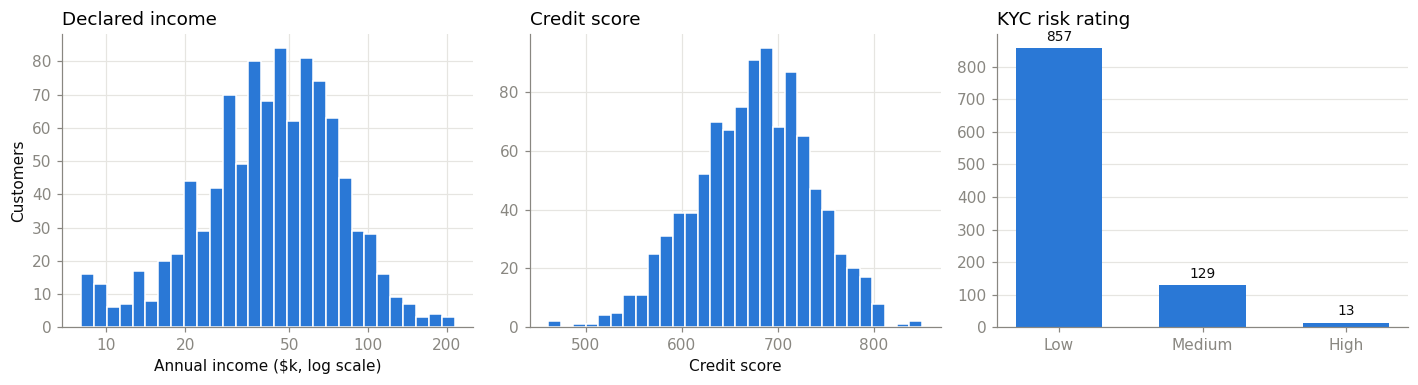

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

axes[0].hist(kyc["annual_income"] / 1000, bins=np.logspace(np.log10(8), np.log10(kyc["annual_income"].max() / 1000), 30),
             color=BLUE, edgecolor="white", linewidth=1)
axes[0].set_xscale("log")
axes[0].set_xticks([10, 20, 50, 100, 200], ["10", "20", "50", "100", "200"])
axes[0].minorticks_off()
axes[0].set_xlabel("Annual income ($k, log scale)")
axes[0].set_ylabel("Customers")
axes[0].set_title("Declared income", loc="left")

axes[1].hist(kyc["credit_score"], bins=30, color=BLUE, edgecolor="white", linewidth=1)
axes[1].set_xlabel("Credit score")
axes[1].set_title("Credit score", loc="left")

ratings = kyc["kyc_risk_rating"].value_counts().reindex(["Low", "Medium", "High"])
bars = axes[2].bar(ratings.index, ratings.values, color=BLUE, width=0.6)
axes[2].bar_label(bars, labels=[f"{v:,}" for v in ratings.values], padding=3, color=INK, fontsize=9)
axes[2].grid(axis="x", visible=False)
axes[2].set_title("KYC risk rating", loc="left")

plt.tight_layout()
plt.show()

## 8. Save

In [10]:
kyc.to_csv(DATA_DIR / "kyc_customers.csv", index=False)
print(f"Wrote {len(kyc):,} customers x {kyc.shape[1]} columns to {DATA_DIR / 'kyc_customers.csv'}")

Wrote 999 customers x 24 columns to data/kyc_customers.csv


## 9. Label-independence check

This is the **only** place `is_fraud` is read, after the table has been saved. Because no field was generated from fraud labels, the **% with any fraud** (the share of a group's customers who had at least one fraudulent transaction at any time) should be roughly the same across KYC groups. Remaining differences are sampling noise (some groups have only a handful of customers) plus any real link through age, job and city size, which the data already contains.

Note that ~98% of customers are defrauded at some point, so this customer-level check is coarse. Sections 4–5 of `supervised.ipynb` measure the KYC fields' value properly, at transaction level: adding them leaves the test PR-AUC unchanged (0.194 → 0.194).

In [11]:
labels = pd.concat([
    pd.read_csv(DATA_DIR / "fraudTrain.csv", usecols=["cc_num", "is_fraud"]),
    pd.read_csv(DATA_DIR / "fraudTest.csv", usecols=["cc_num", "is_fraud"]),
])
# 1 if the customer had at least one fraudulent transaction at any time, else 0
had_any_fraud = labels.groupby("cc_num")["is_fraud"].max().rename("had_any_fraud")
check = kyc.merge(had_any_fraud, on="cc_num")

for column in ["kyc_risk_rating", "employment_status", "id_verification_method"]:
    summary = check.groupby(column)["had_any_fraud"].agg(["size", "sum", "mean"])
    summary.columns = ["customers", "customers with any fraud", "% with any fraud"]
    summary["% with any fraud"] = (summary["% with any fraud"] * 100).round(1)
    display(summary)

,customers,customers with any fraud,% with any fraud
kyc_risk_rating,,,
High,13,13,100.0
Low,857,838,97.8
Medium,129,125,96.9


,customers,customers with any fraud,% with any fraud
employment_status,,,
Employed,688,674,98.0
Retired,164,160,97.6
Self-employed,105,103,98.1
Student,42,39,92.9


,customers,customers with any fraud,% with any fraud
id_verification_method,,,
Database check,252,246,97.6
Document (in person),406,397,97.8
Document + biometric,181,177,97.8
Document upload,160,156,97.5
